# Lab Program 1
## Probability Computation, Conditional Probability & Bayes' Theorem: Simulate and visualize probability experiments, verify addition and multiplication rules, compute conditional probabilities, and apply Bayes' Theorem to real-world classification scenarios. (CO1)

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import itertools

In [46]:
np.random.seed(42)

# --- PART 1A: Classical Probability ---
coin_space = ['H', 'T']
two_coin = list(itertools.product(coin_space, coin_space))
print('Sample Space:', two_coin)

Sample Space: [('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')]


In [47]:
two_heads = [s for s in two_coin if s.count('H') == 2]
P_2H = len(two_heads) / len(two_coin)
print(f'P(2 Heads) = {P_2H}')

P(2 Heads) = 0.25


## PART 1A — Dice Addition Rule
### Now the program demonstrates the addition rule of probability.

In [48]:
# Dice - Addition Rule
dice = list(range(1, 7))
A = [x for x in dice if x % 2 == 0]   # Even
B = [x for x in dice if x > 3]          # Greater than 3
P_A = len(A)/6;  P_B = len(B)/6
P_AB = len(set(A)&set(B))/6
print(f'P(A∪B) = P(A)+P(B)-P(A∩B) = {P_A+P_B-P_AB:.4f}')

P(A∪B) = P(A)+P(B)-P(A∩B) = 0.6667


## PART 1B: Empirical Probability
### Now the program moves from theoretical probability to experimental probability.

In [49]:
# --- PART 1B: Empirical Convergence ---
for n in [10, 100, 1000, 10000]:
    tosses = np.random.binomial(1, 0.5, n)
    print(f'n={n:>6}: P(H)={tosses.mean():.4f}')

n=    10: P(H)=0.6000
n=   100: P(H)=0.4500
n=  1000: P(H)=0.5050
n= 10000: P(H)=0.4940


## PART 1C: Bayes' Theorem
### This is the most important statistical section of the program.
### The example considers a medical diagnostic test.

In [50]:
# --- PART 1C: Bayes' Theorem ---
P_Disease = 0.01    # Only 1% of the population has the disease.
P_Pos_D   = 0.99    # Sensitivity - If a person has the disease, the probability that the test is positive is 99%.
P_Pos_ND  = 0.05    # False Positive Rate - If a person does NOT have the disease, there is still a 5% probability that the test is positive.


# Total Probability
P_Pos = P_Pos_D*P_Disease + P_Pos_ND*(1-P_Disease)
# Bayes' Theorem
P_D_Pos = (P_Pos_D * P_Disease) / P_Pos
print(f'P(Disease | Positive) = {P_D_Pos:.4f} ({P_D_Pos*100:.2f}%)')

P(Disease | Positive) = 0.1667 (16.67%)


# PART 2: Visualization
## The final section demonstrates the Law of Large Numbers visually.

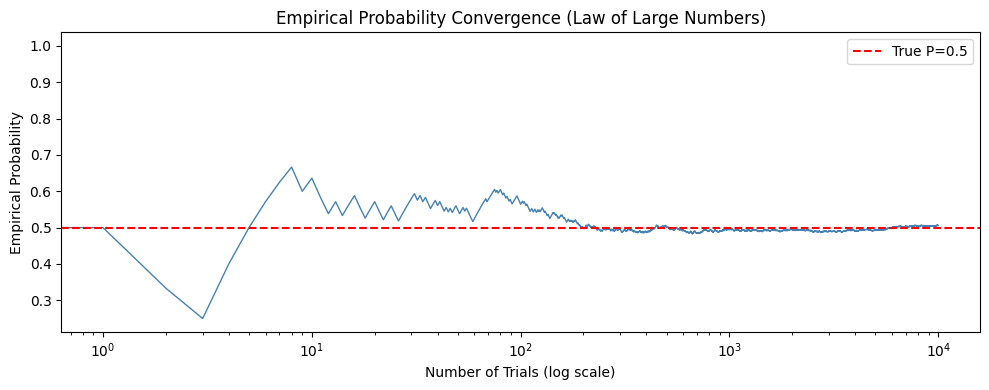

In [51]:
# --- VISUALIZATION ---
# Empirical convergence plot
n_total = 10000
tosses  = np.random.binomial(1, 0.5, n_total)
emp_prob = [tosses[:i].mean() for i in range(1, n_total+1)]
plt.figure(figsize=(10,4))
plt.plot(emp_prob, color='steelblue', linewidth=1)
plt.axhline(0.5, color='red', linestyle='--', label='True P=0.5')
plt.xscale('log')
plt.title('Empirical Probability Convergence (Law of Large Numbers)')
plt.xlabel('Number of Trials (log scale)')
plt.ylabel('Empirical Probability')
plt.legend(); plt.tight_layout(); plt.show()

## Inference from the Graph
### The graph demonstrates the Law of Large Numbers through repeated simulation of a fair coin toss.
- The red dashed line at 0.5 represents the theoretical probability of obtaining Heads.
- For a small number of trials, the empirical probability fluctuates significantly, ranging approximately from 0.25 to 0.67.
- As the number of trials increases, these fluctuations gradually decrease.
- After a few hundred trials, the empirical probability becomes increasingly close to 0.5.
- At around 1,000–10,000 trials, the curve remains very close to the theoretical probability of 0.5.
- Therefore, the graph confirms that as the number of independent trials increases, the empirical probability converges toward the theoretical probability.

The graph clearly demonstrates the Law of Large Numbers. For a small number of trials, the empirical probability of obtaining Heads varies considerably due to random fluctuations. However, as the number of trials increases, the empirical probability gradually converges toward the theoretical probability of 0.5. Hence, a larger number of trials provides a more reliable estimate of the true probability.

# Exercise Questions

1. Coin Toss Probability
Write a Python program to generate the sample space for three coin tosses and calculate the probability of:
- a) Getting exactly 3 Heads
- b) Getting exactly 2 Heads
- c) Getting at least 1 Head
Hint: Use itertools.product().

In [52]:

import itertools

coin_space = ['H', 'T']
sample_space = list(itertools.product(coin_space, repeat=3))
print('Sample Space:', sample_space)

total_outcomes = len(sample_space)
print(f'Total Outcomes: {total_outcomes}')

Sample Space: [('H', 'H', 'H'), ('H', 'H', 'T'), ('H', 'T', 'H'), ('H', 'T', 'T'), ('T', 'H', 'H'), ('T', 'H', 'T'), ('T', 'T', 'H'), ('T', 'T', 'T')]
Total Outcomes: 8


A) Getting exactly 3 Heads

In [53]:
exactly_3 = [s for s in sample_space if s.count('H') == 3]
P_3H = len(exactly_3) / len(sample_space)
print(f'P(3 Heads) = {P_3H}')

P(3 Heads) = 0.125


B) Getting exactly 2 Heads

In [54]:
excatly_2 = [s for s in sample_space if s.count('H') == 2]
P_2H = len(excatly_2) / len(sample_space)
print(f'P(2 Heads) = {P_2H}')

P(2 Heads) = 0.375


C) Getting at least 1 Head

In [55]:
at_least_1 = [s for s in sample_space if 'H' in s]
P_at_least_1 = len(at_least_1) / len(sample_space)
print(f'P(At Least 1 Head) = {P_at_least_1}')

P(At Least 1 Head) = 0.875


2. Dice Probability
Write a Python program to calculate the probability of getting:
- a) An even number
- b) An odd number
- c) A number greater than 4
- d) A number less than or equal to 3
Use the sample space of a single die.

In [56]:
import itertools

dice = [1,2,3,4,5,6]
print('Sample Space:', dice)

total_outcomes = len(dice)
print(f'Total Outcomes: {total_outcomes}')

Sample Space: [1, 2, 3, 4, 5, 6]
Total Outcomes: 6


a) an even number

In [57]:
even_number = [num for num in dice if num % 2 == 0 ]
P_even = len(even_number) / len(dice)
print(f'P(Even Number) = {P_even}')

P(Even Number) = 0.5


b) an odd number

In [58]:
odd_number = [num for num in dice if num % 2 != 0 ]
P_odd = len(odd_number) / len(dice)
print(f'P(odd Number) = {P_odd}')

P(odd Number) = 0.5


c) Greater than 4

In [59]:
greater_than_4 = [num for num in dice if num > 4 ]
P_gt4 = len(greater_than_4) / len(dice)
print(f'P(Greater than 4) = {P_gt4}')

P(Greater than 4) = 0.3333333333333333


d) Less than or equal to 3

In [60]:
less_than_equal_3 = [num for num in dice if num <= 3 ]
P_lte3 = len(less_than_equal_3) / len(dice)
print(f'P(less than equal 3) = {P_lte3}')

P(less than equal 3) = 0.5


3. Two-Dice Experiment
Generate the sample space for rolling two dice and calculate the probability that:
- a) The sum is 7
- b) The sum is greater than 8
- c) Both dice show the same number
- d) At least one die shows 6
Hint: Use itertools.product(range(1,7), range(1,7)).

![SDAV_Lab_Q4.png](attachment:0496b173-357b-4227-89a3-20699b9568fc.png)

In [61]:
dice = (1,2,3,4,5,6)
sample_space = list(itertools.product(dice, dice))
print('Sample Space:', sample_space)

total_outcomes = len(sample_space)
print(f'Total Outcomes: {total_outcomes}')

Sample Space: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6)]
Total Outcomes: 36


A) the sum is 7

In [62]:
sum7 = [s for s in sample_space if (sum(s))==7]
P_sum7 = len(sum7) / total_outcomes
print(f'P(sum is 7) = {P_sum7}')

P(sum is 7) = 0.16666666666666666


B) sum is greater than 8

In [63]:
sum8 = [s for s in sample_space if (sum(s)) > 8]
P_sum8 = len(sum8) / total_outcomes
print(f'P(sum is greater than 8) = {P_sum8}')

P(sum is greater than 8) = 0.2777777777777778


C) Both dice have the same number

In [64]:
same_number = [s for s in sample_space if s[0] == s[1]]
P_same_number = len(same_number) / total_outcomes
print(f'P(Both dice have the same number) = {P_same_number}')

P(Both dice have the same number) = 0.16666666666666666


d) At least one die shows 6

In [65]:
at_least_6_dice = [s for s in sample_space if (6 in s)]
P_at_least_6_dice = len(at_least_6_dice) / total_outcomes
print(f'P(At least one die shows 6) = {P_at_least_6_dice}')

P(At least one die shows 6) = 0.3055555555555556


5. Law of Large Numbers
Simulate 10,000 fair coin tosses and calculate the cumulative probability of Heads after every toss.
Plot:
- X-axis → Number of tosses
- Y-axis → Cumulative probability of Heads
- Horizontal line → \(P(H)=0.5\)
Use a logarithmic X-axis.

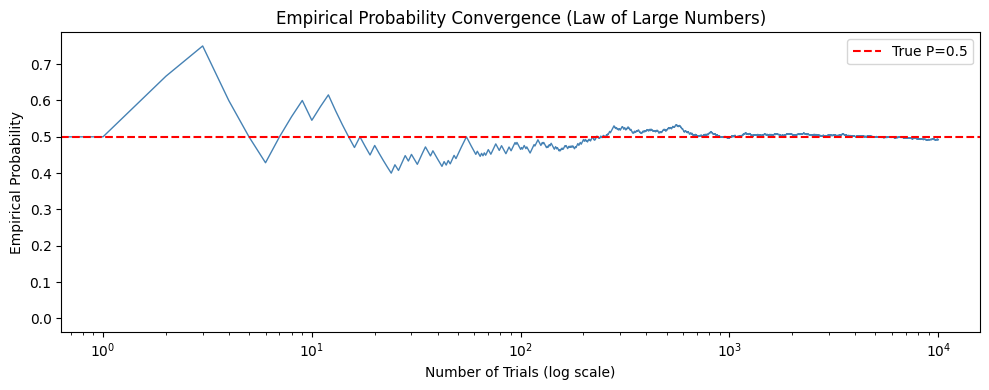

In [66]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n_total = 10000
tosses = np.random.binomial(1, 0.5, n_total)
emp_prob = [tosses[:i].mean() for i in range(1, n_total+1)]
plt.figure(figsize=(10,4))
plt.plot(emp_prob, color='steelblue', linewidth=1)
plt.axhline(0.5, color='red', linestyle='--', label='True P=0.5')
plt.xscale('log')
plt.title('Empirical Probability Convergence (Law of Large Numbers)')
plt.xlabel('Number of Trials (log scale)')
plt.ylabel('Empirical Probability')
plt.legend(); plt.tight_layout(); plt.show()


6. Conditional Probability with Dice
Roll a die.
Define:
- \(A\): number is even
- \(B\): number is greater than 3
- Write a program to calculate: P(A|B)
- Verify the result manually.

In [67]:
sample_space = [1, 2, 3, 4, 5, 6]

# 1. Define the conditions for events A and B
event_A = [num for num in sample_space if num % 2 == 0]
event_B = [num for num in sample_space if num > 3]

# 2. Find the intersection (A and B): outcomes that are BOTH even AND greater than 3
A_intersect_B = [num for num in sample_space if (num % 2 == 0) and (num > 3)]

# 3. Calculate the conditional probability: P(A|B) = len(A ∩ B) / len(B)
prob_A_given_B = len(A_intersect_B) / len(event_B)

print(f"Sample Space:         {sample_space}")
print(f"Event A (Even):       {event_A}")
print(f"Event B (> 3):        {event_B}")
print(f"A ∩ B (Even AND > 3): {A_intersect_B}\n")

print(f"P(A|B) = n(A ∩ B) / n(B) = {len(A_intersect_B)}/{len(event_B)} = {prob_A_given_B:.4f}")

Sample Space:         [1, 2, 3, 4, 5, 6]
Event A (Even):       [2, 4, 6]
Event B (> 3):        [4, 5, 6]
A ∩ B (Even AND > 3): [4, 6]

P(A|B) = n(A ∩ B) / n(B) = 2/3 = 0.6667


### Manual Verification
To verify the result manually, we use the conditional probability formula:
$$P(A|B) = \frac{P(A \cap B)}{P(B)}$$

Alternatively, because all outcomes are equally likely, we can restrict our sample space directly to the outcomes of event $B$:

1. **Find Event B:** The numbers greater than 3 are **[4, 5, 6]**.
   * Total number of outcomes in $B$, $n(B) = \mathbf{3}$.
2. **Find the intersection ($A \cap B$):** Out of those restricted outcomes, which ones are even?
   * The numbers are **[4, 6]**.
   * Total number of favorable outcomes, $n(A \cap B) = \mathbf{2}$.
3. **Calculate the final ratio:**
   $$P(A|B) = \frac{2}{3} \approx \mathbf{0.6667}$$


7. Bayes' Theorem - Medical Test Problem
A disease affects 2% of a population.
A diagnostic test has:
- Sensitivity = 95%
- False-positive rate = 4%
- Write a Python program to calculate: P(Disease|Positive)
- Display the answer as a percentage.

In [68]:
# 1. Define the given probabilities (base rates and test performance)
p_disease = 0.02                    # P(Disease): 2% of the population
p_no_disease = 1 - p_disease        # P(No Disease): 98% of the population

sensitivity = 0.95                  # P(Positive | Disease): 95% True Positive Rate
false_positive_rate = 0.04          # P(Positive | No Disease): 4% False Positive Rate

# 2. Calculate the total probability of testing positive: P(Positive)
# P(+) = P(+ | Disease) * P(Disease) + P(+ | No Disease) * P(No Disease)
p_positive = (sensitivity * p_disease) + (false_positive_rate * p_no_disease)

# 3. Apply Bayes' Theorem to find P(Disease | Positive)
# P(Disease | +) = [P(+ | Disease) * P(Disease)] / P(+)
p_disease_given_positive = (sensitivity * p_disease) / p_positive

# Convert to percentage
percentage_result = p_disease_given_positive * 100



print(f"Disease Prevalence:    {p_disease * 100:.1f}%")
print(f"Test Sensitivity:      {sensitivity * 100:.1f}%")
print(f"False-Positive Rate:   {false_positive_rate * 100:.1f}%\n")

print(f"Total P(Positive Test): {p_positive * 100:.2f}%")
print(f"P(Disease | Positive):  {percentage_result:.2f}%")


Disease Prevalence:    2.0%
Test Sensitivity:      95.0%
False-Positive Rate:   4.0%

Total P(Positive Test): 5.82%
P(Disease | Positive):  32.65%


8. Email Classification
- Suppose: 20% of emails are spam.
- A spam email contains the word "offer" with probability 80%.
- A non-spam email contains offer with probability 10%.
- Using Bayes theorem, calculate: P(Spam|offer)
- Write a Python program to display the result.

In [69]:
# Define given probabilities
p_spam = 0.20
p_non_spam = 1.0 - p_spam

# Likelihoods
p_offer_given_spam = 0.80
p_offer_given_non_spam = 0.10

# 1. Total marginal probability of seeing the word 'offer'
p_offer = (p_offer_given_spam * p_spam) + (p_offer_given_non_spam * p_non_spam)

# 2. Bayes' Theorem calculation for posterior probability
p_spam_given_offer = (p_offer_given_spam * p_spam) / p_offer

# Display the final classification outputs

print(f"Total Probability of 'offer' P(Offer): {p_offer:.2f}")
print(f"Posterior Probability P(Spam | Offer) : {p_spam_given_offer:.4f} ({p_spam_given_offer * 100:.2f}%)")



Total Probability of 'offer' P(Offer): 0.24
Posterior Probability P(Spam | Offer) : 0.6667 (66.67%)
